# stdio와 원격 전송·권한 경계

**이 노트북에서 할 일**

1. 서버 파일을 자식 프로세스로 띄워 stdio로 연결하고, 연결을 닫을 때 서버도 끝나는지 봅니다.
2. 노트북 환경을 통째로 넘긴 서버와, 필요한 이름만 넘긴 서버가 받은 환경 변수를 견줍니다.
3. 서버를 HTTP로 띄우고, 접근 토큰이 없거나 범위가 다를 때 도구 목록과 호출이 어떻게 갈리는지 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
환경 변수 장면에는 실제 키 대신, 노트북이 정한 가짜 이름과 가짜 값을 씁니다.
출력은 모두 서버와 클라이언트가 주고받은 값이라, 다시 실행해도 같은 값이 나와야 합니다.

서버는 실습 폴더 맨 위의 서버 파일 셋을 자식 프로세스로 띄웁니다.
서버 파일 `course_server.py`는 01·02절에서 쓴 파일이고, 나머지 둘은 이 절의 연습 서버 파일입니다.
HTTP 서버는 이 컴퓨터 안의 주소에서만 열고, 마지막 셀에서 끕니다.
노트북이 쓰는 파일은 없고, 걸린 시간은 재지 않았습니다.
앞에서 배운 함수 둘은 도구 파일 `connect_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 fastmcp 4.0.3, mcp 2.2.0, httpx 0.28.1, psutil 7.2.2입니다.
도구 파일이 가져오는 langchain-core는 1.6.2입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
서버 파일을 자식 프로세스로 띄우는 설정과, 넘기는 환경 변수의 Before·After를 보는 자리입니다.
5~7절은 넘길 값을 바꿔 보고 HTTP 서버와 접근 토큰을 다루는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![칸 둘이 나란히 놓인 그림입니다. 왼쪽 칸 stdio 전송에는 파란 상자 노트북 클라이언트 MCP 설정 한 벌에서 표준 입력과 출력이라는 화살표가 초록 상자 자식 프로세스로 띄운 서버로 가고, 그 아래에 초록 상자 서버가 받은 환경 변수 기본 이름과 칸 env가 있습니다. 오른쪽 칸 Streamable HTTP 전송에는 파란 상자 노트북 클라이언트 MCP 주소와 접근 토큰에서 HTTP POST 요청이라는 화살표가 초록 상자 따로 띄운 서버 127.0.0.1의 MCP 주소로 가고, 그 아래에 회색 상자 인증과 인가 접근 토큰과 범위를 봄이 있는 그림](attachment:03-1-두-전송과-넘기는-것.png)

왼쪽 칸이 stdio 전송, 오른쪽 칸이 Streamable HTTP 전송이고, 칸 안은 위에서 아래로 읽습니다.
파란 상자는 우리가 쓴 클라이언트 쪽이고, 초록 상자는 서버 쪽 프로세스와 서버가 받은 값입니다.
칸 맨 아래 상자는 위의 서버에 딸린 것이라 화살표 없이 두었습니다.
왼쪽은 서버가 시작할 때 받은 환경 변수이고, 오른쪽은 서버가 요청마다 하는 일입니다.
회색 상자는 설치판 서버가 하는 일이라, 그 결과는 노트북 6·7절 출력으로 봅니다.
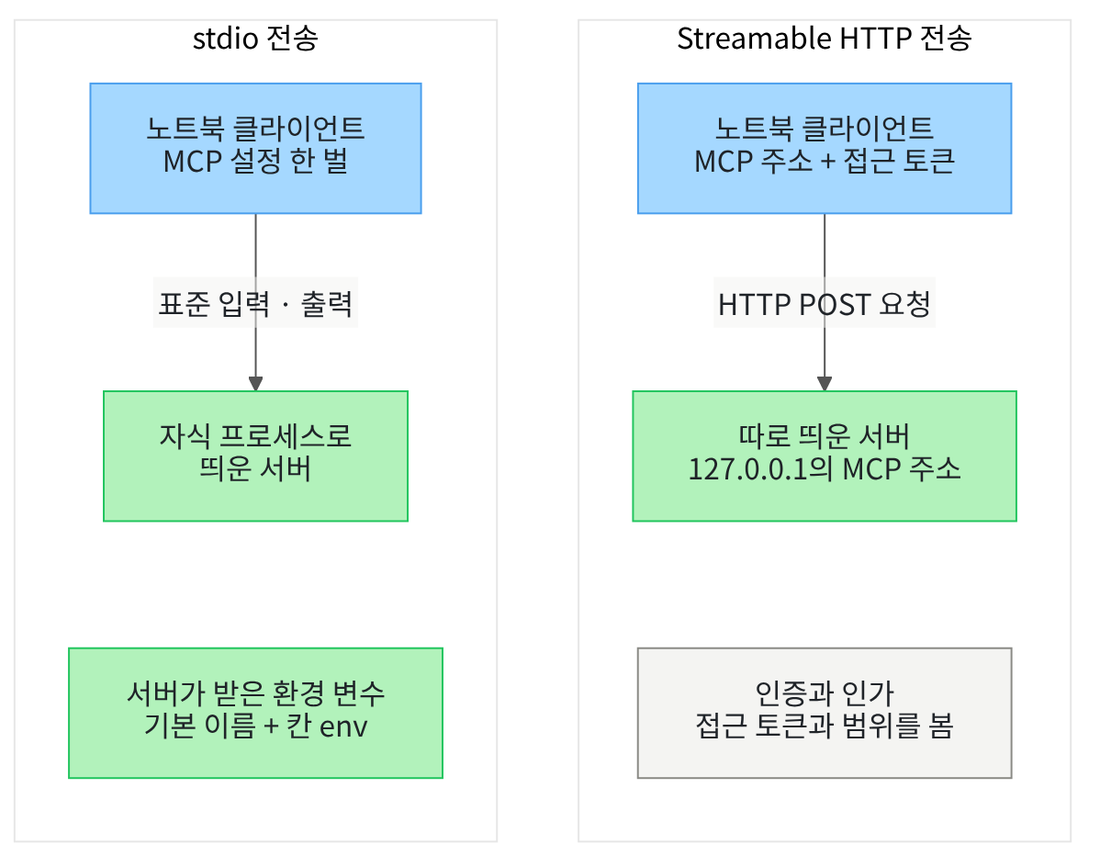

## 1. 준비

이 절은 서버를 노트북 밖의 다른 프로그램으로 띄워 연결합니다.
제목의 stdio는 표준 입력·출력(standard input/output)을 줄인 말입니다.
프로그램이 글을 받는 통로와 내보내는 통로를 뜻하고, 이 전송은 그 두 통로로 메시지를 주고받습니다.
원격 전송은 서버가 네트워크 주소를 여는 방식이고, 이 절에서는 HTTP로 엽니다.
권한 경계는 서버가 받는 값과 허락하는 일의 선입니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
패키지 httpx는 Ch 4 04절에서 HTTP 요청을 보낸 패키지입니다.
패키지 psutil은 실행 중인 프로세스를 살펴보는 패키지입니다.
노트북 도구 ipykernel이 쓰는 패키지라, 실습 폴더 잠금에 이미 들어 있습니다.

패키지 langchain-core는 이 절이 직접 쓰지 않습니다.
도구 파일 `connect_tools.py`가 가져오는 패키지라서 함께 설치합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastmcp==4.0.3" "mcp==2.2.0" "httpx==0.28.1" "psutil==7.2.2" "langchain-core==1.6.2"
from importlib.metadata import version

print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))
print("httpx:", version("httpx"))
print("psutil:", version("psutil"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
fastmcp: 4.0.3
mcp: 2.2.0
httpx: 0.28.1
psutil: 7.2.2
langchain-core: 1.6.2


**결과 읽기** — 출력 줄 `fastmcp: 4.0.3`, `mcp: 2.2.0`, `httpx: 0.28.1`, `psutil: 7.2.2`, `langchain-core: 1.6.2`가 보입니다.
다섯 판 모두 실습 폴더 잠금과 같습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `os`·`socket`·`subprocess`·`sys`·`time`은 Python에 들어 있는 모듈입니다.
오류 종류 `MCPError`는 연결 단계에서 거절되면 클라이언트가 받는 오류입니다.
클래스 `StreamableHttpTransport`는 HTTP 서버에 붙는 방법 하나를 담는 클래스이고, 7절에서 풉니다.

함수 `get_default_environment`는 MCP 파이썬 SDK가 stdio 서버에 늘 넘기는 기본 이름을 딕셔너리로 내놓고, 6절에서 씁니다.
마지막 가져오기 줄은 앞 절에서 배운 함수 둘을 도구 파일 `connect_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·socket·subprocess·sys·time은 Python에 들어 있는 모듈입니다)
import os
import socket
import subprocess
import sys
import time
import httpx
import psutil
from fastmcp import Client
from fastmcp.client.transports import StreamableHttpTransport
from mcp import MCPError
from mcp.client.stdio import get_default_environment
from connect_tools import call_tool_row, names_of

print("가져온 도구 파일 함수:", "call_tool_row, names_of")

가져온 도구 파일 함수: call_tool_row, names_of


**결과 읽기** — 출력 줄 `가져온 도구 파일 함수: call_tool_row, names_of`가 보입니다.
함수 `names_of`는 01절 4절에서 만든 함수로, 목록의 항목마다 이름을 모읍니다.
함수 `call_tool_row`는 02절 2절에서 만든 함수로, 도구 하나를 부르고 결과나 오류를 딕셔너리로 담습니다.

앞에서 배운 함수는 `connect_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

## 2. 서버 파일을 자식 프로세스로 띄우기

01·02절은 서버 객체를 같은 노트북 안에서 메모리로 연결했습니다.
이 절은 서버 파일을 다른 프로그램으로 실행하고, 그 프로그램과 표준 입력·출력으로 메시지를 주고받습니다.
Ch 23 04절은 한 프로그램이 띄운 또 하나의 프로그램을 자식 프로세스라고 불렀습니다.
먼저 01절 2절과 같은 셀로 서버 파일의 위치를 찾습니다.

In [3]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 같은 폴더에 있는 연습 서버 파일 둘의 위치를 만듭니다.
함수 `os.path.dirname`은 파일 위치에서 폴더 부분만 꺼냅니다.
함수 `os.path.join`은 폴더와 파일 이름을 이어 붙입니다.

In [4]:
# 서버 파일이 있는 실습 폴더에서, 이 절이 띄울 연습 서버 파일 둘의 위치를 만듭니다
lab_folder = os.path.dirname(server_file)
env_server_file = os.path.join(lab_folder, "env_server.py")
auth_server_file = os.path.join(lab_folder, "auth_server.py")
print("환경 확인 서버 파일이 있는가:", os.path.exists(env_server_file))
print("권한 연습 서버 파일이 있는가:", os.path.exists(auth_server_file))

환경 확인 서버 파일이 있는가: True
권한 연습 서버 파일이 있는가: True


**결과 읽기** — 출력 줄 `환경 확인 서버 파일이 있는가: True`와 `권한 연습 서버 파일이 있는가: True`가 보입니다.
두 파일은 이 절을 위해 실습 폴더 맨 위에 둔 연습 서버입니다.
파일 `env_server.py`는 자기가 받은 환경 변수를 알려 주는 도구 둘을 가진 서버입니다.
파일 `auth_server.py`는 접근 토큰을 확인하는 HTTP 서버이고, 6·7절에서 씁니다.

세 서버 파일 모두 맨 끝에 `if __name__ == "__main__":` 줄이 있습니다.
파일을 직접 실행할 때만 그 아래 줄이 돌고, 그 줄이 서버를 엽니다.
02절에서 `runpy.run_path`로 읽었을 때는 이 줄 아래가 돌지 않았습니다.

자식 프로세스로 띄운 FastMCP 서버는 시작할 때 시작 안내를 표준 오류로 내보냅니다.
그때 인터넷에서 새 판이 있는지도 확인합니다.
다음 셀은 이 두 가지를 끄고 기록 수준을 올리는 환경 변수 셋을 딕셔너리로 만듭니다.
환경 변수(environment variable)는 프로그램이 시작할 때 받는 이름과 값의 목록입니다.

In [5]:
# 자식 프로세스로 띄운 FastMCP 서버가 시작 안내와 새 판 확인을 하지 않게 하는 환경 변수 셋입니다
quiet_env = {
    "FASTMCP_SHOW_SERVER_BANNER": "false",
    "FASTMCP_CHECK_FOR_UPDATES": "off",
    "FASTMCP_LOG_LEVEL": "WARNING",
}
print("조용히 하는 이름:", list(quiet_env))

조용히 하는 이름: ['FASTMCP_SHOW_SERVER_BANNER', 'FASTMCP_CHECK_FOR_UPDATES', 'FASTMCP_LOG_LEVEL']


**결과 읽기** — 라벨 `조용히 하는 이름:` 뒤에 이름 셋이 보입니다.
모두 `FASTMCP_`로 시작하고, 서버 쪽 FastMCP는 이 앞머리가 붙은 환경 변수를 설정으로 읽습니다.
값은 차례대로 시작 안내 끄기, 새 판 확인 끄기, 경고보다 낮은 기록 남기지 않기입니다.

다음 셀은 서버 파일 하나를 stdio로 띄우는 설정 한 벌을 만드는 함수입니다.
칸 `command`는 실행할 프로그램, 칸 `args`는 그 프로그램에 넘길 인자입니다.
칸 `env`는 서버에 넘길 환경 변수입니다.
칸 `keep_alive`를 `False`로 두면, 연결을 닫을 때 서버도 끝납니다.
바깥 칸 `mcpServers` 아래에 서버 이름 하나로 설정을 담는 것이 FastMCP 설정 딕셔너리의 모양입니다.

In [6]:
# 서버 파일 하나를 stdio로 띄우는 MCP 설정 한 벌을 만들어 내놓습니다
def stdio_config(server_path, env):
    settings = {
        "command": sys.executable,
        "args": [server_path],
        "env": env,
        "keep_alive": False,
    }
    return {"mcpServers": {"server": settings}}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `command`의 `sys.executable`은 지금 커널을 실행하는 Python의 파일 위치입니다.
그래서 서버도 같은 가상환경의 Python으로 실행되고, 같은 패키지 판을 씁니다.
서버 이름 `server`는 이 설정 안에서 서버를 부르는 이름일 뿐입니다.

다음 셀은 01·02절 서버 파일을 이 설정으로 띄워 연결합니다.
01절에서 본 것처럼, 연결은 `async with` 블록을 벗어날 때 닫힙니다.
블록 안과 밖에서, 이 노트북이 띄운 자식 프로세스 수를 셉니다.
함수 `psutil.Process()`는 지금 커널 프로세스를 객체로 내놓습니다.
그 메서드 `children`은 이 프로세스의 자식 프로세스 목록을 내놓습니다.

실행 전에 예상해 봅니다.
블록을 벗어난 뒤에도 서버 프로세스가 남아 있을까요?

In [7]:
# 서버 파일을 자식 프로세스로 띄워 연결하고, 블록 안과 밖에서 자식 프로세스 수를 셉니다
kernel_process = psutil.Process()
course_config = stdio_config(server_file, quiet_env)
async with Client(course_config) as client:
    course_tools = await client.list_tools()
    children_inside = kernel_process.children()
children_after = kernel_process.children()
print("받은 도구 이름:", names_of(course_tools))
print("블록 안에서 자식 프로세스 수:", len(children_inside))
print("블록을 벗어난 뒤 자식 프로세스 수:", len(children_after))

받은 도구 이름: ['lookup_policy']
블록 안에서 자식 프로세스 수: 1
블록을 벗어난 뒤 자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `받은 도구 이름: ['lookup_policy']`가 보입니다.
01절 메모리 연결에서 받은 도구와 같은 이름입니다.
출력 줄 `블록 안에서 자식 프로세스 수: 1`과 `블록을 벗어난 뒤 자식 프로세스 수: 0`도 보입니다.
연결하는 동안에만 서버 프로세스 하나가 돌았고, 블록을 벗어나자 끝났습니다.

칸 `keep_alive`의 기본값은 `True`입니다.
기본값으로 두면 블록을 벗어난 뒤에도 자식 프로세스 하나가 남았습니다.
이 장면은 노트북 밖의 작은 스크립트로만 확인했고, 이 노트북에서는 실행하지 않았습니다.

다음 셀은 같은 설정으로 도구 `lookup_policy`를 부릅니다.
02절에서 만든 함수 `call_tool_row`에 서버 객체 대신 설정 딕셔너리를 넘깁니다.
이 함수는 받은 값을 클래스 `Client`에 그대로 넘기므로, 설정 딕셔너리도 받습니다.
부를 때마다 연결을 새로 열고 닫아, 서버도 새로 떴다가 끝납니다.

In [8]:
# 같은 설정으로 도구 lookup_policy를 부르고, 부른 뒤 자식 프로세스 수를 셉니다
course_row = await call_tool_row(course_config, "lookup_policy", {"topic": "대출"})
children_now = kernel_process.children()
print("도구를 부른 결과:", course_row)
print("자식 프로세스 수:", len(children_now))

도구를 부른 결과: {'받은 것': '결과', '글 줄': ['일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.']}
자식 프로세스 수: 0


**결과 읽기** — 받은 것은 `'결과'`이고, 글 줄에 `일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.`가 있습니다.
01절 4절에서 메모리 연결로 받은 결과 글과 같은 글입니다.
출력 줄 `자식 프로세스 수: 0`으로, 이번 연결의 서버도 끝났습니다.
도구를 찾는 방법과 부르는 방법은 전송이 달라도 같았습니다.

## 3. 환경을 통째로 넘긴 서버 (Before)

자식 프로세스는 부모 프로세스가 넘긴 환경 변수를 받아 시작합니다.
Ch 6 01절 이후 키 셀은 함수 `load_dotenv()`로 `.env` 파일의 키를 노트북 환경 변수로 읽어 들였습니다.
그런 노트북에서 환경을 통째로 서버에 넘기면, 그 키도 서버 프로세스에 들어갑니다.
이 절은 실제 키 대신, 노트북이 정한 가짜 이름과 가짜 값으로 이 장면을 봅니다.

다음 셀은 노트북 환경에 가짜 이름 `CH28_DEMO_TOKEN`과 가짜 값을 넣습니다.
모듈 os의 `os.environ`은 이 노트북 프로세스의 환경 변수를 이름과 값으로 담은 객체입니다.
딕셔너리처럼 키로 값을 넣고, `in`으로 이름이 있는지 봅니다.

In [9]:
# 노트북 환경에 교재용 가짜 이름과 가짜 값을 넣습니다(실제 키가 아닙니다)
fake_name = "CH28_DEMO_TOKEN"
os.environ[fake_name] = "교재용-가짜-값"
print("노트북 환경에 가짜 이름이 있는가:", fake_name in os.environ)

노트북 환경에 가짜 이름이 있는가: True


**결과 읽기** — 출력 줄 `노트북 환경에 가짜 이름이 있는가: True`가 보입니다.
이름과 값은 모두 이 셀에서 정한 교재용 글이고, 실제 서비스의 키가 아닙니다.

다음 셀은 Before 설정을 만들어 환경 확인 서버를 띄웁니다.
함수 `dict`로 노트북 환경 전체를 딕셔너리로 복사하고, 메서드 `update`로 조용히 하는 세 이름을 더합니다.
이 딕셔너리를 칸 `env`에 넣고, 서버의 도구 `env_names`를 부릅니다.
이 도구는 서버 프로세스가 받은 환경 변수 이름을 한 줄에 하나씩 알려 줍니다.
실제 키 이름이 섞일 수 있어, 이름 목록은 출력하지 않고 가짜 이름이 있는지만 봅니다.

In [10]:
# Before: 노트북 환경을 통째로 복사해 넘기는 설정으로 환경 확인 서버를 띄우고, 받은 이름을 봅니다
before_env = dict(os.environ)
before_env.update(quiet_env)
before_config = stdio_config(env_server_file, before_env)
before_names = await call_tool_row(before_config, "env_names", {})
# 실제 키 이름이 섞일 수 있어, 이름 목록은 출력하지 않고 가짜 이름이 있는지만 봅니다
print("받은 것:", before_names["받은 것"])
print("서버가 받은 이름에 가짜 이름이 있는가:", fake_name in before_names["글 줄"])

받은 것: 결과
서버가 받은 이름에 가짜 이름이 있는가: True


**결과 읽기** — 출력 줄 `서버가 받은 이름에 가짜 이름이 있는가: True`가 보입니다.
노트북에서 정한 가짜 이름이 서버 프로세스까지 넘어갔습니다.
이 서버는 가짜 이름을 쓸 일이 없는데도 받았습니다.

다음 셀은 노트북 환경의 이름 가운데 서버가 받지 못한 이름을 셉니다.
목록 `before_names["글 줄"]`에 없는 이름만 모읍니다.

In [11]:
# 노트북 환경의 이름 가운데 서버가 받지 못한 이름을 모읍니다(이름은 출력하지 않고 수만 봅니다)
before_missing = []
for name in os.environ:
    if name not in before_names["글 줄"]:
        before_missing.append(name)
print("서버가 받지 못한 노트북 이름 수:", len(before_missing))

서버가 받지 못한 노트북 이름 수: 0


**결과 읽기** — 출력 줄 `서버가 받지 못한 노트북 이름 수: 0`이 보입니다.
노트북 환경의 이름이 하나도 빠짐없이 서버로 넘어갔습니다.
이 노트북에 키가 들어 있었다면, 그 키도 함께 넘어갔을 것입니다.

다음 셀은 서버의 도구 `env_value`에 가짜 이름을 넣어 부릅니다.
이 도구는 서버 프로세스가 그 이름으로 받은 값을 알려 줍니다.
실행 전에 예상해 봅니다.
서버 쪽 코드가 가짜 값까지 읽을 수 있을까요?

In [12]:
# 서버 도구 env_value에 가짜 이름을 넣어, 서버 프로세스가 그 값까지 읽는지 봅니다
before_value = await call_tool_row(before_config, "env_value", {"name": fake_name})
print("서버가 읽은 값:", before_value["글 줄"])

서버가 읽은 값: ['교재용-가짜-값']


**결과 읽기** — 출력 줄 `서버가 읽은 값: ['교재용-가짜-값']`이 보입니다.
서버 쪽 코드가 노트북에서 넣은 값을 그대로 읽었습니다.
이것이 이 절의 Before 결함입니다.

연습 서버는 값을 보여 주려고 도구로 꺼냈지만, 도구가 없어도 서버 코드는 `os.environ`으로 값을 읽습니다.
실제 서버라면 그 값을 기록에 남기거나 다른 곳으로 보낼 수도 있고, 노트북은 그것을 막지 못합니다.
그래서 서버에 무엇을 넘길지는 서버를 띄우는 쪽이 정해야 합니다.

## 4. 필요한 이름만 넘긴 서버 (After)

After 설정은 칸 `env`에 조용히 하는 세 이름만 넣습니다.
서버 파일과 도구, 부르는 셀은 Before와 같고, 다른 것은 칸 `env`의 딕셔너리 하나입니다.
After 서버가 받은 이름에는 실제 키가 섞일 자리가 없어, 목록을 그대로 출력합니다.

실행 전에 예상해 봅니다.
서버는 이름 셋만 받을까요?

In [13]:
# After: 조용히 하는 세 이름만 넘기는 설정으로 같은 서버를 띄우고, 서버 프로세스의 환경 변수 이름을 봅니다
after_config = stdio_config(env_server_file, quiet_env)
after_names = await call_tool_row(after_config, "env_names", {})
print("서버가 받은 이름에 가짜 이름이 있는가:", fake_name in after_names["글 줄"])
# 이름의 수와 목록은 기기와 운영 체제에 따라 다릅니다
print("서버 프로세스의 환경 변수 이름:")
print(after_names["글 줄"])

서버가 받은 이름에 가짜 이름이 있는가: False
서버 프로세스의 환경 변수 이름:
['FASTMCP_CHECK_FOR_UPDATES', 'FASTMCP_LOG_LEVEL', 'FASTMCP_SHOW_SERVER_BANNER', 'HOME', 'LC_CTYPE', 'LOGNAME', 'PATH', 'SHELL', 'TERM', 'USER']


**결과 읽기** — 출력 줄 `서버가 받은 이름에 가짜 이름이 있는가: False`가 보입니다.
라벨 `서버 프로세스의 환경 변수 이름:` 아래 목록에는 우리가 적은 `FASTMCP_` 이름 셋이 있고, 가짜 이름은 없습니다.

교재 출력의 목록에는 적지 않은 이름도 있습니다.
이름 여섯 `HOME`·`LOGNAME`·`PATH`·`SHELL`·`TERM`·`USER`는 MCP 파이썬 SDK가 늘 넘기는 기본 이름입니다.
이 SDK는 기본 이름 가운데 노트북 환경에 있는 것만 넘기고, 칸 `env`에 적은 이름을 그 위에 더합니다.
남은 `LC_CTYPE`은 받은 이름이 아니라, 서버 쪽 Python이 시작하며 스스로 만든 이름입니다.
그래서 이 목록과 이름의 수는 기기와 운영 체제에 따라 다르고, Windows는 기본 이름부터 다릅니다.

다음 셀은 After 서버의 도구 `env_value`에 같은 가짜 이름을 넣어 부릅니다.

In [14]:
# After 서버의 도구 env_value에 같은 가짜 이름을 넣어 부릅니다
after_value = await call_tool_row(after_config, "env_value", {"name": fake_name})
print("서버가 읽은 값:", after_value["글 줄"])

서버가 읽은 값: ['없음']


**결과 읽기** — 출력 줄 `서버가 읽은 값: ['없음']`이 보입니다.
서버 프로세스에 가짜 이름이 없어, 서버 코드가 그 값을 읽지 못했습니다.
두 도구는 Before와 같이 답했고, 서버가 볼 수 있는 값만 줄었습니다.

## 5. 값 바꿔 보기: 넘길 이름 하나 적어 넣기

서버에 정말 키가 필요할 때도 있습니다.
서버 도구가 다른 서비스를 부른다면 그 서비스의 키가 있어야 합니다.
MCP 규격 문서도 stdio 서버는 자격 정보(credentials)를 환경에서 가져온다고 적습니다.
바꿀 값은 칸 `env`의 딕셔너리이고, 조용히 하는 세 이름에 가짜 이름 하나만 더 적습니다.

실행 전에 예상해 봅니다.
After 서버와 견주어, 서버가 받은 이름은 몇 개 늘어날까요?

In [15]:
# 넘길 딕셔너리만 바꿔, 조용히 하는 세 이름에 가짜 이름 하나를 더 적어 넘깁니다
vary_env = dict(quiet_env)
vary_env[fake_name] = os.environ[fake_name]
vary_config = stdio_config(env_server_file, vary_env)
vary_names = await call_tool_row(vary_config, "env_names", {})
vary_value = await call_tool_row(vary_config, "env_value", {"name": fake_name})
# 같은 기기에서 After 서버와 견주어, 이름이 몇 개 늘었는지만 봅니다
added_count = len(vary_names["글 줄"]) - len(after_names["글 줄"])
print("서버가 받은 이름에 가짜 이름이 있는가:", fake_name in vary_names["글 줄"])
print("After보다 늘어난 이름 수:", added_count)
print("서버가 읽은 값:", vary_value["글 줄"])

서버가 받은 이름에 가짜 이름이 있는가: True
After보다 늘어난 이름 수: 1
서버가 읽은 값: ['교재용-가짜-값']


**결과 읽기** — 출력 줄 `서버가 받은 이름에 가짜 이름이 있는가: True`, `After보다 늘어난 이름 수: 1`, `서버가 읽은 값: ['교재용-가짜-값']`이 보입니다.
After 서버가 받은 이름에, 적어 넣은 가짜 이름 하나만 더해졌습니다.
늘어난 수는 같은 기기에서 두 설정을 견준 값이라, 기본 이름이 몇 개인지와 상관이 없습니다.
칸 `env`에 적은 이름은 넘어가고, 적지 않은 이름은 넘어가지 않습니다.
넘길 이름을 하나씩 적어 두면, 코드만 읽어도 서버가 받는 이름이 보입니다.

다음 셀은 노트북 환경에서 가짜 이름을 지우고, 자식 프로세스가 남았는지 봅니다.
문장 `del`은 딕셔너리에서 키 하나를 지우는 문장이고, 환경 변수에도 같게 씁니다.

In [16]:
# 노트북 환경에서 가짜 이름을 지우고, 이 절에서 띄운 자식 프로세스가 남았는지 봅니다
del os.environ[fake_name]
children_now = kernel_process.children()
print("노트북 환경에 가짜 이름이 있는가:", fake_name in os.environ)
print("자식 프로세스 수:", len(children_now))

노트북 환경에 가짜 이름이 있는가: False
자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `노트북 환경에 가짜 이름이 있는가: False`와 `자식 프로세스 수: 0`이 보입니다.
이 절에서 stdio로 띄운 서버는 모두 연결을 닫을 때 끝났습니다.
가짜 이름은 3~5절에서만 쓰므로 여기서 지웠습니다.

## 6. HTTP로 띄운 서버와 인증

이번에는 서버를 HTTP 서버로 따로 띄웁니다.
전송 Streamable HTTP에서는 서버가 네트워크 주소 하나(MCP 주소)를 엽니다.
클라이언트는 메시지마다 HTTP POST 요청을 그 주소로 보냅니다.
전송 stdio와 달리 서버가 먼저 떠 있어, 여러 클라이언트가 같은 주소로 붙을 수 있습니다.

그래서 서버는 요청을 보낸 쪽이 누구인지 먼저 확인합니다.
이 확인을 인증(authentication)이라고 부릅니다.
건물 입구에서 출입증을 보여 주는 일과 같습니다.
이 절의 서버는 요청 헤더에 실린 접근 토큰(access token)으로 인증합니다.
헤더(header)는 HTTP 요청과 응답의 본문 앞에 붙는 이름과 값 줄입니다.

다음 셀은 서버가 포트를 열 때까지 기다리는 함수입니다.
Ch 23 04절의 함수 `wait_for_signal`은 신호 파일이 생길 때까지 짧게 쉬며 봤습니다.
이 함수는 파일 대신 포트에 연결해 보고, 연결되면 `True`를 내놓습니다.
함수 `socket.socket()`은 연결 하나를 만들고, 메서드 `connect_ex`는 연결에 성공하면 0을 내놓습니다.
블록 `with`는 Ch 2 05절의 `with open`처럼, 블록을 벗어날 때 연결을 닫습니다.

In [17]:
# 서버가 포트를 열 때까지 짧게 쉬며 연결해 보고, 기한 안에 열렸는지를 True·False로 내놓습니다
def wait_for_port(port, limit_seconds):
    check_interval = 0.05
    deadline = time.perf_counter() + limit_seconds
    while time.perf_counter() < deadline:
        with socket.socket() as probe:
            if probe.connect_ex(("127.0.0.1", port)) == 0:
                return True
        time.sleep(check_interval)
    return False

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 컴퓨터 자신을 가리키는 주소 `127.0.0.1`의 포트에만 연결해 봅니다.
기한 안에 열리지 않으면 `False`를 내놓아, 셀이 끝없이 기다리지 않습니다.
이 함수는 그 포트에서 누군가 듣고 있는지만 보고, 누가 듣는지는 가리지 않습니다.

다음 셀은 권한 연습 서버를 띄울 주소와 명령, 넘길 환경 변수를 정합니다.
넘길 환경 변수는 SDK 기본 이름에 조용히 하는 세 이름을 더한 딕셔너리입니다.
3~5절에서 본 것처럼 넘길 이름을 적어 두어, 노트북 환경을 통째로 넘기지 않습니다.
그리고 서버를 띄우기 전에, 그 포트에서 이미 듣는 프로그램이 있는지 봅니다.
다른 프로그램이 포트를 쥐고 있으면 새 서버는 포트를 열지 못하고, 앞 프로그램이 대신 답하게 됩니다.

In [18]:
# 권한 연습 서버를 띄울 주소·명령·환경 변수를 정하고, 띄우기 전에 그 포트가 비어 있는지 봅니다
auth_port = 58028
auth_url = "http://127.0.0.1:" + str(auth_port) + "/mcp"
command = [sys.executable, auth_server_file, str(auth_port)]
# stdio 서버처럼, SDK 기본 이름과 조용히 하는 세 이름만 넘깁니다(노트북 환경을 통째로 넘기지 않음)
http_env = get_default_environment()
http_env.update(quiet_env)
check_limit = 1
port_in_use = wait_for_port(auth_port, check_limit)
print("띄우기 전에 이 포트에서 듣는 프로그램이 있는가:", port_in_use)
assert not port_in_use, "다른 프로그램이 이 포트를 쓰고 있습니다. 셀의 포트 번호를 바꿔 이 셀부터 다시 실행합니다."

띄우기 전에 이 포트에서 듣는 프로그램이 있는가: False


**결과 읽기** — 출력 줄 `띄우기 전에 이 포트에서 듣는 프로그램이 있는가: False`가 보입니다.
포트가 비어 있어, 셀 끝의 `assert`를 지났습니다.
이 줄이 참으로 나오면 셀이 멈추니, 그때는 셀의 포트 번호를 바꿔 이 셀부터 다시 실행합니다.

다음 셀은 권한 연습 서버 파일을 HTTP 서버로 띄웁니다.
함수 `subprocess.Popen`은 Ch 23 04절처럼 프로그램을 켜 두고, 끝나기를 기다리지 않습니다.
인자 `env`에 앞 셀의 딕셔너리를 넘기고, 서버가 표준 출력과 표준 오류로 내보내는 기록은 버립니다.
인자로 넘긴 포트 번호는 서버 파일 맨 끝 줄이 읽어, 이 컴퓨터 안의 주소에서만 서버를 엽니다.
포트가 열린 뒤에는 메서드 `poll`로, 띄운 서버가 아직 돌고 있는지도 봅니다.

In [19]:
# 권한 연습 서버 파일을 HTTP 서버로 띄우고, 포트가 열렸는지와 띄운 서버가 살아 있는지 봅니다(서버 기록은 버림)
auth_process = subprocess.Popen(command, env=http_env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
port_limit = 20
server_ready = wait_for_port(auth_port, port_limit)
# 메서드 poll은 프로그램이 아직 돌고 있으면 None을 내놓습니다
server_alive = auth_process.poll() is None
children_now = kernel_process.children()
print("서버가 준비되었는가:", server_ready)
print("띄운 서버가 살아 있는가:", server_alive)
print("자식 프로세스 수:", len(children_now))
assert server_ready, "기한 안에 서버가 포트를 열지 않았습니다. 커널을 다시 시작해 앞 셀부터 실행합니다."
assert server_alive, "띄운 서버가 끝났습니다. 앞 셀로 이 포트를 다른 프로그램이 쓰는지 다시 봅니다."

서버가 준비되었는가: True
띄운 서버가 살아 있는가: True
자식 프로세스 수: 1


**결과 읽기** — 출력 줄 `서버가 준비되었는가: True`, `띄운 서버가 살아 있는가: True`, `자식 프로세스 수: 1`이 보입니다.
HTTP 서버 하나가 자식 프로세스로 떠서 포트를 열었고, 지금도 돌고 있습니다.
이 서버는 연결 블록과 상관없이 떠 있고, 우리가 끌 때까지 돕니다.

이 셀만 두 번 실행하면, 앞에서 띄운 서버가 포트를 쥔 채 남습니다.
새로 띄운 서버는 포트를 열지 못해 곧 끝나고, 이름 `auth_process`는 끝난 서버를 가리킵니다.
그래서 다시 실행할 때는 마지막 셀로 서버를 끈 뒤 앞 셀부터 실행하고, 끄지 못했으면 커널을 다시 시작합니다.

다음 셀은 접근 토큰 없이 연결해 봅니다.
연결에서 오류가 나면 이름 `MCPError`만 받아, 셀이 멈추지 않게 합니다.
실행 전에 예상해 봅니다.
도구 목록을 받을 수 있을까요?

In [20]:
# 접근 토큰 없이 연결해 도구 목록을 받아 봅니다(연결 오류 MCPError만 받습니다)
try:
    async with Client(auth_url) as client:
        no_token_tools = await client.list_tools()
except MCPError as error:
    print("받은 것:", type(error).__name__)
    print("받은 글:", str(error))

받은 것: MCPError
받은 글: Server returned an error response


**결과 읽기** — 받은 것은 `MCPError`이고, 받은 글은 `Server returned an error response`입니다.
도구 목록을 받기 전에 연결에서 거절되었습니다.
02절에서 본 `ToolError`는 도구를 부를 때의 오류였고, 이 오류는 연결 단계의 오류입니다.
받은 글만으로는 왜 거절됐는지 드러나지 않습니다.

다음 셀은 같은 MCP 주소에 접근 토큰 없는 HTTP 요청을 직접 한 번 보냅니다.
함수 `httpx.post`는 Ch 4 04절의 `httpx.get`과 같은 모양으로 POST 요청을 보냅니다.
응답의 상태 코드와, 응답 헤더 하나를 봅니다.

In [21]:
# 같은 MCP 주소에 접근 토큰 없는 HTTP 요청을 직접 한 번 보내, 상태 코드와 응답 헤더 하나를 봅니다
raw_response = httpx.post(auth_url)
print("HTTP 상태 코드:", raw_response.status_code)
print("WWW-Authenticate 헤더:", raw_response.headers["www-authenticate"])

HTTP 상태 코드: 401
WWW-Authenticate 헤더: Bearer


**결과 읽기** — 출력 줄 `HTTP 상태 코드: 401`과 `WWW-Authenticate 헤더: Bearer`가 보입니다.
상태 코드 401은 요청한 쪽이 누구인지 확인하지 못했다는 뜻입니다.
헤더 값 `Bearer`는 요청 헤더에 접근 토큰을 실어 보내라는 표시입니다.
서버는 요청 본문을 보기 전에 인증부터 했습니다.

앞 셀의 클라이언트가 받은 상태 코드는 노트북에서 출력하지 않았습니다.
설치판 MCP 파이썬 SDK는 상태 코드 400 이상을 받으면, 상태 코드를 적지 않은 앞 셀의 글로 오류를 만듭니다.
그래서 거절된 까닭을 볼 때는 이 셀처럼 상태 코드를 직접 봅니다.

## 7. 접근 토큰의 범위와 인가

인증을 지난 요청에게 무엇을 허락할지 정하는 일을 인가(authorization)라고 부릅니다.
출입증으로 건물에 들어온 뒤에도, 층마다 들어갈 수 있는 사람이 정해진 것과 같습니다.
이 절의 서버는 접근 토큰에 적힌 범위(scope)로 인가합니다.
범위는 접근 토큰이 허락받은 일의 이름입니다.
읽기 토큰 `reader-token-demo`에는 `read`, 관리 토큰 `admin-token-demo`에는 `read`와 `admin`이 적혀 있습니다.

서버 파일 `auth_server.py`에서 쓰기 도구를 붙이는 줄은 `@mcp.tool(auth=require_scopes("admin"))`입니다.
이 줄은 아래 함수를 도구로 등록하면서, 범위 `admin`이 있는 요청에게만 보이게 합니다.
읽기 도구 `lookup_policy`는 범위를 따지지 않고, 인증을 지난 요청이면 누구에게나 보입니다.

다음 셀은 두 접근 토큰으로 서버에 붙는 방법 둘을 만들고, 읽기 토큰으로 도구 목록을 받습니다.
클래스 `StreamableHttpTransport`는 MCP 주소와 접근 토큰을 함께 담습니다.
이 객체를 클래스 `Client`에 서버 대신 넘기면, 요청마다 헤더에 접근 토큰을 싣습니다.

In [22]:
# 접근 토큰 둘로 서버에 붙는 방법 둘을 만들고, 읽기 토큰으로 도구 목록을 받습니다
reader_server = StreamableHttpTransport(auth_url, auth="reader-token-demo")
admin_server = StreamableHttpTransport(auth_url, auth="admin-token-demo")
async with Client(reader_server) as client:
    reader_tools = await client.list_tools()
print("읽기 토큰으로 받은 도구:", names_of(reader_tools))

읽기 토큰으로 받은 도구: ['lookup_policy']


**결과 읽기** — 출력 줄 `읽기 토큰으로 받은 도구: ['lookup_policy']`가 보입니다.
서버에는 도구가 둘 있지만, 읽기 토큰에게는 쓰기 도구가 목록에서 빠졌습니다.
Ch 19 06절의 함수 `pick_tools`는 클라이언트 쪽에서 쓰기 도구를 목록에 넣지 않았습니다.
이 절은 서버가 접근 토큰의 범위를 보고 목록에서 뺐습니다.

목록에 없는 도구도 이름을 알면 부를 수 있을까요?
다음 셀은 읽기 토큰으로 쓰기 도구 `update_policy`를 불러 보고, 읽기 도구도 부릅니다.
바꿀 글은 평일 운영 시간의 끝을 한 시간 늦춘 교재용 글입니다.

In [23]:
# 읽기 토큰으로 목록에 없던 쓰기 도구를 불러 보고, 읽기 도구도 불러 봅니다
update_args = {"topic": "운영", "text": "평일은 09:00~21:00, 토요일은 10:00~17:00에 운영합니다."}
reader_update = await call_tool_row(reader_server, "update_policy", update_args)
reader_lookup = await call_tool_row(reader_server, "lookup_policy", {"topic": "운영"})
print("쓰기 도구를 부른 결과:", reader_update)
print("읽기 도구를 부른 결과:", reader_lookup)

쓰기 도구를 부른 결과: {'받은 것': 'ToolError', '글 줄': ["Unknown tool: 'update_policy'"]}
읽기 도구를 부른 결과: {'받은 것': '결과', '글 줄': ['평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.']}


**결과 읽기** — 쓰기 도구를 부른 결과는 `ToolError`이고, 글은 `Unknown tool: 'update_policy'`입니다.
02절 2절에서 붙이지 않은 함수를 불렀을 때와 같은 모양의 글입니다.
서버는 범위가 모자란 요청에게 이 도구를 없는 도구처럼 대했습니다.
읽기 도구는 결과를 냈고, 글 줄에 `평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.`가 있습니다.

다음 셀은 관리 토큰으로 도구 목록을 받고, 같은 쓰기 도구를 같은 인자로 부릅니다.

In [24]:
# 관리 토큰으로 도구 목록을 받고, 같은 쓰기 도구를 같은 인자로 부릅니다
async with Client(admin_server) as client:
    admin_tools = await client.list_tools()
admin_update = await call_tool_row(admin_server, "update_policy", update_args)
print("관리 토큰으로 받은 도구:", names_of(admin_tools))
print("쓰기 도구를 부른 결과:", admin_update)

관리 토큰으로 받은 도구: ['lookup_policy', 'update_policy']
쓰기 도구를 부른 결과: {'받은 것': '결과', '글 줄': ['규정을 바꿨습니다: 운영']}


**결과 읽기** — 출력 줄 `관리 토큰으로 받은 도구: ['lookup_policy', 'update_policy']`가 보입니다.
범위 `admin`이 있는 접근 토큰에게는 쓰기 도구도 보였습니다.
쓰기 도구를 부른 결과는 `'결과'`이고, 글 줄은 `['규정을 바꿨습니다: 운영']`입니다.

다음 셀은 읽기 토큰으로 운영 규정을 다시 읽습니다.
실행 전에 예상해 봅니다.
읽기 토큰이 받는 글도 바뀌었을까요?

In [25]:
# 읽기 토큰으로 운영 규정을 다시 읽어, 관리 토큰이 바꾼 글이 보이는지 봅니다
reader_again = await call_tool_row(reader_server, "lookup_policy", {"topic": "운영"})
print("읽기 도구를 부른 결과:", reader_again)

읽기 도구를 부른 결과: {'받은 것': '결과', '글 줄': ['평일은 09:00~21:00, 토요일은 10:00~17:00에 운영합니다.']}


**결과 읽기** — 받은 글 줄은 `['평일은 09:00~21:00, 토요일은 10:00~17:00에 운영합니다.']`입니다.
관리 토큰이 바꾼 글을 읽기 토큰도 그대로 받았습니다.
규정은 서버 한 곳에 있고, 인가는 누가 그 규정을 바꿀 수 있는지를 정했습니다.

마지막 셀은 HTTP 서버를 끕니다.
메서드 `terminate`는 프로그램에 끝내라는 신호를 보냅니다.
Ch 23 04절의 `kill`은 곧바로 끊었고, 이 신호는 서버가 하던 일을 정리하고 끝날 기회를 줍니다.
메서드 `wait`는 프로그램이 끝날 때까지 기다려 종료 코드를 내놓습니다.

In [26]:
# HTTP 서버에 끝내라는 신호를 보내고, 끝날 때까지 기다려 종료 코드를 봅니다
auth_process.terminate()
stop_limit = 10
return_code = auth_process.wait(timeout=stop_limit)
children_now = kernel_process.children()
print("종료 코드:", return_code)
print("자식 프로세스 수:", len(children_now))
print("포트가 아직 열려 있는가:", wait_for_port(auth_port, check_limit))

종료 코드: -15
자식 프로세스 수: 0


포트가 아직 열려 있는가: False


**결과 읽기** — 출력 줄 `종료 코드: -15`와 `자식 프로세스 수: 0`이 보입니다.
음수 종료 코드는 신호를 받아 끝났다는 표시이고, 15는 끝내라는 신호의 번호입니다.
출력 줄 `포트가 아직 열려 있는가: False`로, 서버가 연 포트도 닫혔습니다.

## 정리

1. 서버 파일을 stdio로 띄워도 도구를 찾고 부르는 방법은 같았고, 연결을 닫자 서버도 끝났습니다.
2. 환경을 통째로 넘긴 서버는 가짜 값까지 읽었고, 세 이름만 넘긴 서버는 가짜 이름을 받지 않았습니다.
3. HTTP 서버는 접근 토큰 없는 요청을 401로 거절했고, 읽기 토큰에게는 쓰기 도구를 숨겼습니다.

04절에서는 서버의 MCP 도구를 LangChain 도구로 바꾸고, 에이전트에 붙여 봅니다.